In [3]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, silhouette_score, davies_bouldin_score
)
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.neighbors import KNeighborsClassifier

from clean_data import load_and_clean
import features_transactions as ft

from select_features import (split, prune, stable_groups, compare_sets)


## Data Set Build

In [4]:
RANDOM_STATE = 0

TARGET = "target_value"
OBS_ID = "obs_id"
CUSTOMER_ID = "cifwithcheckdigit"
M0_DATE = "m0_monthenddate"

N_CLUSTERS = 7
N_NEIGHBORS = 7
TEST_SIZE = 0.20
PERMUTATION_REPEATS = 5
MAX_OBSERVATIONS = None  # set to an integer for a quick test run
OUT_DIR = Path("analysis_outputs_salary_and_spending")

In [5]:
clients, transactions, report = load_and_clean("snapshot/snapshot.parquet")
obs = pd.read_parquet('output/obs_features.parquet')

Observation key: ['obs_id']
Observation-level columns (17): ['cifwithcheckdigit', 'obs_seq', 'm0_monthenddate', 'm0_arrearsamount', 'crccreditlimit', 'due_count', 'payment_count', 'm0_total_due_with_arrears', 'total_paid', 'target_value', 'target_rule', 'new_to_arrears_flag', 'product_group', 'm0_start_cd_group', 'payment_date', 'collectionsmethodname', 'exclude_flag']
Transaction-level columns (8): ['days_from_payment', 'tx_period', 'transactiondate', 'trantypedesc', 'amount', 'balance', 'spendgroup', 'categoryname']
Ignored when matching duplicates (row counters): []
Building clients table ...
  4,482,046 raw rows -> 10,499 observations (4,999 customers) (2s)
Building transactions table ...
  transactions batch 1/1: 3,534,387 rows kept (3s)
CLIENTS (one row per observation)                                             
  raw rows (observation fields repeated per transaction)             4,482,046
  observations after cleaning                                           10,499
  distinct

In [6]:
ft.WINDOW_DAYS = np.inf

X_features = ft.build_running_features(
    clients=clients,
    txns=transactions,
    as_of=0,
    batch_customers=20_000,
    by_group=True,
    log_money=True,
    verbose=True,
)

print("Feature matrix:", X_features.shape)

  running features batch 1/1 done
Feature matrix: (10499, 142)


In [7]:
EXCLUDE_EXACT = {
    TARGET, "target_rule", "total_paid", "payment_count",
    OBS_ID, CUSTOMER_ID, M0_DATE,
}
EXCLUDE_PREFIXES = ("target_",)

meta = clients.set_index(OBS_ID)
ids = X_features.index.intersection(meta.index)

X = X_features.loc[ids].copy()
y = meta.loc[ids, TARGET].copy()
groups = meta.loc[ids, CUSTOMER_ID].copy()

valid = y.notna() & groups.notna()
X, y, groups = X.loc[valid], y.loc[valid], groups.loc[valid]

drop_cols = [
    c for c in X.columns
    if c in EXCLUDE_EXACT or any(str(c).startswith(p) for p in EXCLUDE_PREFIXES)
]
X = X.drop(columns=drop_cols, errors="ignore")

for col in X.select_dtypes(include=["bool"]).columns:
    X[col] = X[col].astype("int8")

X = X.replace([np.inf, -np.inf], np.nan)
print("Model observations:", len(X))
print("Predictor columns:", X.shape[1])
print("Overall target rate:", round(y.mean(), 4))

Model observations: 10499
Predictor columns: 141
Overall target rate: 0.5194


In [8]:
tr, te = split(y, groups)                                   # obs_id lists, customer-grouped
pr   = prune(X, tr, y)                                         # 1. aliases, constants, correlated families
print(pr["table"])                                             #    what was dropped and why
st   = stable_groups(X, y, groups, tr, pr["groups"])        # 2. which families matter, repeatedly, on unseen customers
print(st["table"])
sets = {"all": list(X.columns), "pruned": pr["keep"], "selected": st["keep"]}
print(compare_sets(X, y, groups, tr, te, sets))             # 3. same split, same model, fewer inputs

prune: 141 -> 59 inputs  (constant 0, alias 56, correlated 26); 20 families with >1 member
                           feature reason         kept_instead  abs_spearman
0                          balance  alias         balance_slog           1.0
1                       run_income  alias      run_income_slog           1.0
2                        run_spend  alias       run_spend_slog           1.0
3                   run_essentials  alias  run_essentials_slog           1.0
4                      run_outflow  alias     run_outflow_slog           1.0
..                             ...    ...                  ...           ...
136   run_in_savings_drawdown_slog   kept                                NaN
137  run_in_refunds_windfalls_slog   kept                                NaN
138       run_in_other_inflow_slog   kept                                NaN
139           run_max_balance_slog   kept                                NaN
140                   balance_slog   kept                     

In [9]:
X_pruned = X[pr["keep"]] 

In [10]:
def to_snapshot_id(values, lookup):
    # normalise: text, no whitespace, no trailing ".0" from float ids
    s = pd.Series(values).astype(str).str.strip().str.replace(r"\.0$", "", regex=True)
    return s.map(lookup).to_numpy()

mapping = pd.read_csv("snapshot/snapshot_obs_id_map.csv", dtype=str)
mapping = mapping.rename(columns={"old_obs_id": "original_id", "obs_id": "snapshot_id"})
mapping["original_id"] = mapping["original_id"].str.strip()
lookup = mapping.set_index("original_id")["snapshot_id"]

if "obs_id" in obs.columns:                      # obs_id is a column
    print("sample ids in obs:", obs["obs_id"].head(3).tolist(), "| dtype:", obs["obs_id"].dtype)
    new = to_snapshot_id(obs["obs_id"], lookup)
    print(f"{pd.isna(new).sum():,} rows had no mapping")
    obs["obs_id"] = new
else:                                            # obs_id is the index
    print("sample ids in index:", obs.index[:3].tolist(), "| dtype:", obs.index.dtype)
    new = to_snapshot_id(obs.index, lookup)
    print(f"{pd.isna(new).sum():,} rows had no mapping")
    obs.index = pd.Index(new, name="obs_id")


sample ids in obs: [167, 168, 169] | dtype: int32
0 rows had no mapping


In [18]:
X_merged = obs.merge(X_pruned.reset_index(), "left", OBS_ID).set_index(OBS_ID)
X_final = X_merged.drop(columns=drop_cols, errors="ignore")
X_final = X_final.drop(columns=[TARGET, "target_rule", "exclude_flag"])

## Data Cleaning

In [19]:
# 3. Drop the raw date columns in obs
X_final = X_final.drop(columns=["payment_date", "m0_monthenddate"], errors="ignore")

In [20]:
# Dropping product_group because i think theres only PDM and m0_start_cd_group because in numeric form it 1-to-1 with obs_seq
X_final = X_final.drop(columns=["m0_start_cd_group", "product_group"], errors="ignore")

In [21]:
# Converting pay_frequency to numeric
per_month = {"weekly": 4.33, "fortnightly": 2.17, "monthly": 1.0}
X_final["pays_per_month"] = X_final["pay_frequency"].map(per_month)   # NaN for irregular/unknown
X_final["pay_irregular"] = (X_final["pay_frequency"] == "irregular").astype(int)
X_final["pay_unknown"] = (X_final["pay_frequency"] == "unknown").astype(int)
X_final = X_final.drop(columns=["pay_frequency"], errors="ignore")

In [22]:
# One-hot encoding income type
X_final = pd.get_dummies(X_final, columns=["income_type_p0"], prefix="inc_p0", dtype=float)
X_final = pd.get_dummies(X_final, columns=["income_type_p1"], prefix="inc_p1", dtype=float)
X_final = pd.get_dummies(X_final, columns=["income_type_p2"], prefix="inc_p2", dtype=float)

In [23]:
new_cols = ['obs_seq','new_to_arrears_flag','crccreditlimit','periods_with_income','recency_weighted_income',
            'income_cv','pay_gap_mean','pay_gap_cv','n_cycles','avg_spend_between_pays','avg_spend_ratio',
            'avg_spend_per_day','avg_days_to_half','avg_first3_share','last_income_change','recent_vs_avg_income',
            'bal7_ratio_last','bal7_ratio_avg','bal7_ratio_change','income_p0','n_payments_p0','income_p1',
            'n_payments_p1','income_p2','n_payments_p2','no_income_detected','no_bal7_history','no_complete_cycle',
            'pays_per_month','pay_irregular','pay_unknown'] + \
           [c for c in X.columns if c.startswith(("inc_p0_","inc_p1_","inc_p2_"))]

new_cols = [c for c in new_cols if c in X_final.columns]
assert X_final.index.is_unique, "X must have one row per obs_id"

old_cols = list(pr["keep"])                 # the 54 from your earlier prune (or your stable set)
tr, te   = split(y, groups)

# 1. Do the new features carry information the old ones don't?
pr_all = prune(X_final[old_cols + new_cols], tr, y)
t = pr_all["table"]
print(t[t.feature.isin(new_cols)].sort_values("reason"))

prune: 90 -> 88 inputs  (constant 0, alias 0, correlated 2); 2 families with >1 member
                    feature reason kept_instead  abs_spearman
41           crccreditlimit   kept                        NaN
60                  obs_seq   kept                        NaN
61      new_to_arrears_flag   kept                        NaN
62      periods_with_income   kept                        NaN
63  recency_weighted_income   kept                        NaN
64                income_cv   kept                        NaN
65             pay_gap_mean   kept                        NaN
66               pay_gap_cv   kept                        NaN
67                 n_cycles   kept                        NaN
68   avg_spend_between_pays   kept                        NaN
69          avg_spend_ratio   kept                        NaN
70        avg_spend_per_day   kept                        NaN
71         avg_days_to_half   kept                        NaN
72         avg_first3_share   kept           

In [25]:
# 2. Which families are stable on unseen customers? (judge with kNN and logistic, keep the union)
st_k = stable_groups(X_final, y, groups, tr, pr_all["groups"], kind="knn",   n_splits=10, min_t=2.0)
st_l = stable_groups(X_final, y, groups, tr, pr_all["groups"], kind="logit", n_splits=10, min_t=2.0)
keep = sorted(set(st_k["keep"]) | set(st_l["keep"]))

for name, st in (("knn", st_k), ("logit", st_l)):
    print(name); print(st["table"][st["table"].index.isin(new_cols)].round(4))

# 3. Do they add accuracy over the old set? Same split, same models.
new_kept = [c for c in keep if c in new_cols]
sets = {"old (pruned)":  old_cols,
        "new (kept)":    new_kept,
        "old + new kept": sorted(set(old_cols) | set(new_kept)),
        "selected (all)": keep}
print(compare_sets(X_final, y, groups, tr, te, sets).round(3))

stable_groups (knn): 88 families -> 13 kept (positive in >= 80% of 10 folds and t >= 2.0)
stable_groups (logit): 88 families -> 14 kept (positive in >= 80% of 10 folds and t >= 2.0)
knn
                           mean      sd  frac_folds_positive  family_size  \
new_to_arrears_flag      0.0091  0.0043                  1.0            1   
income_cv                0.0077  0.0051                  1.0            1   
recent_vs_avg_income     0.0073  0.0065                  0.9            1   
no_bal7_history          0.0033  0.0059                  0.8            1   
obs_seq                  0.0033  0.0059                  0.8            1   
crccreditlimit           0.0031  0.0043                  0.8            2   
pay_gap_mean             0.0030  0.0045                  0.6            1   
income_p2                0.0028  0.0036                  0.8            1   
income_p1                0.0027  0.0024                  0.9            1   
pay_gap_cv               0.0023  0.0061     

In [27]:
X_done = X_final[keep]
X_done.columns

Index(['avg_spend_between_pays', 'bal7_ratio_last', 'crccreditlimit',
       'days_since_last_income', 'grp_communication_share', 'income_cv',
       'income_p1', 'income_p2', 'n_cycles', 'n_spend_groups_used',
       'new_to_arrears_flag', 'no_income_detected', 'no_income_seen',
       'pay_gap_mean', 'recent_vs_avg_income', 'run_grp_debt_repayment_slog',
       'run_grp_family_education_slog', 'run_in_income_informal_slog',
       'run_in_transfers_in_slog', 'run_income_slog', 'run_n_bounced',
       'run_n_cash', 'run_n_gambling', 'spend_to_income'],
      dtype='str')

## Clustering done on unpruned features

In [15]:
from sklearn.base import BaseEstimator, TransformerMixin

# Scaling pipeline
class Winsorizer(BaseEstimator, TransformerMixin):
    """Clip each column to its [lo, hi] percentiles, learned on the fitted data only."""
    def __init__(self, lo=1, hi=99):
        self.lo, self.hi = lo, hi

    def fit(self, X, y=None):
        X = np.asarray(X, dtype="float64")
        self.lo_ = np.nanpercentile(X, self.lo, axis=0)
        self.hi_ = np.nanpercentile(X, self.hi, axis=0)
        return self

    def transform(self, X):
        return np.clip(np.asarray(X, dtype="float64"), self.lo_, self.hi_)


prep = make_pipeline(
    SimpleImputer(strategy="median"),     # NaN -> median (use strategy="constant", fill_value=0 for zeros)
    Winsorizer(lo=1, hi=99),              # tame extreme values
    StandardScaler(),                     # mean 0, sd 1 for every column
)

X_clean = X_final.replace([np.inf, -np.inf], np.nan)
Z = prep.fit_transform(X_clean)

# check it worked: every column should have sd close to 1 (constant columns will be 0)
print(pd.DataFrame(Z).std().describe())

km = KMeans(n_clusters=6, n_init=10, random_state=0).fit(Z)
labels = km.labels_
print(pd.Series(labels).value_counts().sort_index())

count    120.000000
mean       0.991714
std        0.091291
min        0.000000
25%        1.000048
50%        1.000048
75%        1.000048
max        1.000048
dtype: float64
0    1159
1    2691
2    2129
3     528
4    2945
5    1047
Name: count, dtype: int64


## KMeans

,inertia,silhouette,davies_bouldin
k,,,
2,1092831.854,0.139,2.417
3,1031423.370,0.080,2.930
4,988452.017,0.082,2.689
5,953116.119,0.070,2.781
6,925909.066,0.075,2.792
7,900629.763,0.065,2.671
8,875858.497,0.076,2.545
9,853649.716,0.081,2.567
10,840628.829,0.082,2.556


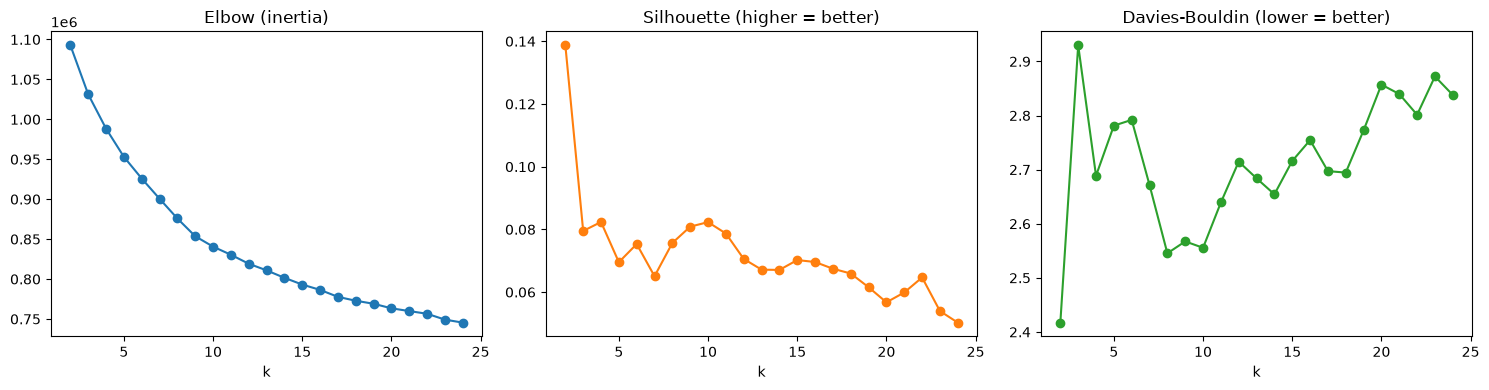

In [16]:
SIL_SAMPLE = min(10_000, len(Z))
ks = range(2, 25)
rows = []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Z)
    rows.append({'k': k, 'inertia': km.inertia_,
                 'silhouette': silhouette_score(Z, km.labels_, sample_size=SIL_SAMPLE,
                                                random_state=RANDOM_STATE),
                 'davies_bouldin': davies_bouldin_score(Z, km.labels_)})
scores = pd.DataFrame(rows).set_index('k')
display(scores.round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(ks, scores['inertia'], marker='o')
axes[0].set(title='Elbow (inertia)', xlabel='k')
axes[1].plot(ks, scores['silhouette'], marker='o', color='tab:orange')
axes[1].set(title='Silhouette (higher = better)', xlabel='k')
axes[2].plot(ks, scores['davies_bouldin'], marker='o', color='tab:green')
axes[2].set(title='Davies-Bouldin (lower = better)', xlabel='k')
plt.tight_layout()
plt.show()

In [17]:
# Z = the scaled matrix from the pipeline; X_clean = the DataFrame it was built from
km2 = KMeans(n_clusters=2, n_init=10, random_state=0).fit(Z)
labels = km2.labels_

# 1. Cluster sizes
sizes = pd.Series(labels).value_counts().sort_index()
print(pd.DataFrame({"n": sizes, "share": (sizes / len(labels)).round(3)}))

# 2. Top driving features: the gap between the two centroids, in standard-deviation units
# (Z is standardised, so centroid values are already z-scores)
centres = pd.DataFrame(km2.cluster_centers_, columns=X_clean.columns, index=["c0", "c1"])
drivers = (centres.loc["c1"] - centres.loc["c0"]).rename("c1_minus_c0")
top = drivers.reindex(drivers.abs().sort_values(ascending=False).index).head(15)
print(top.round(3))

# 3. The same features in original units, so you can read them
profile = X_clean.assign(cluster=labels).groupby("cluster")[top.index.tolist()].median().T
print(profile.round(2))

      n  share
0  3221  0.307
1  7278  0.693
n_spend_groups_used               1.651
run_nonessential_slog             1.475
run_essentials_slog               1.450
run_grp_p2p_payments_slog         1.385
run_income_slog                   1.359
run_grp_communication_slog        1.350
run_grp_food_groceries_slog       1.344
periods_with_income               1.321
spend_group_entropy               1.307
run_grp_eating_out_slog           1.298
run_grp_personal_shopping_slog    1.295
days_since_last_income           -1.283
run_in_transfers_in_slog          1.259
run_in_income_other_slog          1.214
no_complete_cycle                -1.193
Name: c1_minus_c0, dtype: float64
cluster                             0      1
n_spend_groups_used              7.00  14.00
run_nonessential_slog            5.26   9.00
run_essentials_slog              7.06   9.72
run_grp_p2p_payments_slog        3.93   9.53
run_income_slog                  8.39  10.77
run_grp_communication_slog       3.14   7.11
run_gr

## Decision Tree

In [18]:
from sklearn.metrics import log_loss, roc_auc_score
from sklearn.tree import DecisionTreeClassifier, export_text

cols = X_clean.columns
prep = make_pipeline(SimpleImputer(strategy="median"), Winsorizer(1, 99))
Ztr, Zte = prep.fit_transform(X_clean.loc[tr]), prep.transform(X_clean.loc[te])

tree = DecisionTreeClassifier(max_leaf_nodes=25, min_samples_leaf=int(0.03 * len(tr)), random_state=0).fit(Ztr, y.loc[tr])
print(export_text(tree, feature_names=cols))        # the rules, in original units (no scaling needed for trees)

ltr, lte = tree.apply(Ztr), tree.apply(Zte)
rate = pd.Series(y.loc[tr].to_numpy()).groupby(ltr).mean()
pte  = pd.Series(lte).map(rate).to_numpy()
print("test AUC:", round(roc_auc_score(y.loc[te], pte), 3), "| log-loss:", round(log_loss(y.loc[te], pte, labels=[0, 1]), 4))

|--- income_p0 <= 2993.22
|   |--- run_n_bounced <= 4.50
|   |   |--- recent_vs_avg_income <= 0.52
|   |   |   |--- class: 1
|   |   |--- recent_vs_avg_income >  0.52
|   |   |   |--- balance_slog <= 6.13
|   |   |   |   |--- run_in_borrowing_slog <= 6.97
|   |   |   |   |   |--- avg_spend_between_pays <= 14602.08
|   |   |   |   |   |   |--- new_to_arrears_flag <= 0.50
|   |   |   |   |   |   |   |--- class: 1
|   |   |   |   |   |   |--- new_to_arrears_flag >  0.50
|   |   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |--- avg_spend_between_pays >  14602.08
|   |   |   |   |   |   |--- class: 1
|   |   |   |   |--- run_in_borrowing_slog >  6.97
|   |   |   |   |   |--- class: 1
|   |   |   |--- balance_slog >  6.13
|   |   |   |   |--- class: 0
|   |--- run_n_bounced >  4.50
|   |   |--- income_p0 <= 260.50
|   |   |   |--- run_in_income_informal_slog <= 6.04
|   |   |   |   |--- class: 1
|   |   |   |--- run_in_income_informal_slog >  6.04
|   |   |   |   |--- run_grp_debt_r

## Log Regression

In [19]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import adjusted_rand_score

def fit_eval(a_ids, b_ids, k, weighted=True, floor=0.1, alpha=1, seed=0):
    prep = make_pipeline(SimpleImputer(strategy="median"), Winsorizer(1, 99), StandardScaler())
    Za, Zb = prep.fit_transform(X_clean.loc[a_ids]), prep.transform(X_clean.loc[b_ids])
    ya, yb = y.loc[a_ids], y.loc[b_ids]
    w = np.ones(Za.shape[1])
    if weighted:
        c = np.abs(LogisticRegression(C=0.1, max_iter=2000).fit(Za, ya).coef_[0])
        w = floor + (1 - floor) * c / c.max()
    km = KMeans(k, n_init=10, random_state=seed).fit(Za * w)
    la, lb = km.labels_, km.predict(Zb * w)
    s = pd.DataFrame({"c": la, "y": ya.to_numpy()}).groupby("c")["y"].agg(["sum", "count"])
    rate = ((s["sum"] + alpha) / (s["count"] + 2 * alpha)).reindex(range(k)).fillna(ya.mean())
    pb = rate.to_numpy()[lb]
    res = {"k": k, "weighted": weighted, "logloss": log_loss(yb, pb, labels=[0, 1]), "auc": roc_auc_score(yb, pb),
           "rate_spread": rate.max() - rate.min(), "min_share": np.bincount(la, minlength=k).min() / len(la)}
    return res, km, la, rate, lb          # lb = cluster labels of the b_ids rows

In [20]:
tr, te = split(y, groups)
K = 7
res, km, la, rate, lb = fit_eval(tr, te, K, weighted=True)
print({k: round(float(v), 4) for k, v in res.items()})

{'k': 7.0, 'weighted': 1.0, 'logloss': 0.6417, 'auc': 0.6791, 'rate_spread': 0.5414, 'min_share': 0.0364}


In [21]:
prep = make_pipeline(SimpleImputer(strategy="median"), Winsorizer(1, 99), StandardScaler())
Ztr, Zte = prep.fit_transform(X_clean.loc[tr]), prep.transform(X_clean.loc[te])
p_lg = LogisticRegression(C=0.1, max_iter=2000).fit(Ztr, y.loc[tr]).predict_proba(Zte)[:, 1]

print(pd.DataFrame({
    "model": ["weighted clusters", "logistic (same inputs)"],
    "test_auc": [res["auc"], roc_auc_score(y.loc[te], p_lg)],
    "test_logloss": [res["logloss"], log_loss(y.loc[te], p_lg)]}).round(4))

                    model  test_auc  test_logloss
0       weighted clusters    0.6791        0.6417
1  logistic (same inputs)    0.7832        0.5589


In [22]:
rows = []
for s in range(1, 6):                                   # different K-means starts
    r, _, _, _, lb_s = fit_eval(tr, te, K, True, seed=s)
    rows.append({"test": "kmeans seed", "run": s, "ARI_vs_base": adjusted_rand_score(lb, lb_s),
                 "auc": r["auc"], "logloss": r["logloss"]})
for s in range(1, 6):                                   # different 80% subsets of the training customers
    sub, _ = split(y.loc[tr], groups, test_size=0.2, seed=s)
    r, _, _, _, lb_s = fit_eval(sub, te, K, True)
    rows.append({"test": "80% of customers", "run": s, "ARI_vs_base": adjusted_rand_score(lb, lb_s),
                 "auc": r["auc"], "logloss": r["logloss"]})

stab = pd.DataFrame(rows)
print(stab.round(3).to_string(index=False))
print(stab.groupby("test")["ARI_vs_base"].agg(["mean", "min"]).round(3))

            test  run  ARI_vs_base   auc  logloss
     kmeans seed    1        1.000 0.679    0.642
     kmeans seed    2        0.615 0.691    0.633
     kmeans seed    3        0.959 0.677    0.643
     kmeans seed    4        1.000 0.679    0.642
     kmeans seed    5        0.987 0.679    0.642
80% of customers    1        0.576 0.701    0.625
80% of customers    2        0.538 0.690    0.630
80% of customers    3        0.570 0.696    0.631
80% of customers    4        0.573 0.694    0.629
80% of customers    5        0.874 0.677    0.643
                   mean    min
test                          
80% of customers  0.626  0.538
kmeans seed       0.912  0.615


In [23]:
def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z**2 / n; c = (p + z**2 / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return c - h, c + h

t = pd.DataFrame({"c": lb, "y": y.loc[te].to_numpy()}).groupby("c")["y"].agg(["sum", "count"])
lo, hi = wilson(t["sum"].to_numpy(), t["count"].to_numpy())
seg = pd.DataFrame({"n_test": t["count"], "share": t["count"] / t["count"].sum(),
                    "rate_train": rate.reindex(t.index).to_numpy(),
                    "rate_test": t["sum"] / t["count"], "ci_low": lo, "ci_high": hi}
                   ).sort_values("rate_test", ascending=False)
print(seg.round(3))

# What defines each segment, in original units (the 15 features that differ most between segments)
med = X_clean.loc[te].assign(c=lb).groupby("c").median()
top = ((med.max() - med.min()) / X_clean.loc[te].std()).sort_values(ascending=False).head(15).index
print(med.loc[seg.index, top].T.round(2))

   n_test  share  rate_train  rate_test  ci_low  ci_high
c                                                       
1     260  0.124       0.691      0.762   0.706    0.809
3      90  0.043       0.811      0.689   0.587    0.775
4     540  0.257       0.670      0.626   0.584    0.666
2     594  0.283       0.498      0.544   0.504    0.583
6     276  0.132       0.338      0.301   0.250    0.357
5     274  0.131       0.295      0.281   0.231    0.337
0      64  0.031       0.269      0.266   0.173    0.385
c                                 1      3        4        2        6  \
no_income_detected             0.00   1.00     0.00     0.00     0.00   
no_income_seen                 0.00   1.00     0.00     0.00     0.00   
run_income_slog                7.60   0.00     9.52    10.66    10.58   
run_essentials_slog            6.20   0.00     8.52     9.89     9.28   
run_in_income_other_slog       7.49   0.00     9.22    10.48     9.20   
periods_with_income            2.00   0.00     3.

## Clustering done on final pruned features

In [30]:
from sklearn.base import BaseEstimator, TransformerMixin

# Scaling pipeline
class Winsorizer(BaseEstimator, TransformerMixin):
    """Clip each column to its [lo, hi] percentiles, learned on the fitted data only."""
    def __init__(self, lo=1, hi=99):
        self.lo, self.hi = lo, hi

    def fit(self, X, y=None):
        X = np.asarray(X, dtype="float64")
        self.lo_ = np.nanpercentile(X, self.lo, axis=0)
        self.hi_ = np.nanpercentile(X, self.hi, axis=0)
        return self

    def transform(self, X):
        return np.clip(np.asarray(X, dtype="float64"), self.lo_, self.hi_)


prep = make_pipeline(
    SimpleImputer(strategy="median"),     # NaN -> median (use strategy="constant", fill_value=0 for zeros)
    Winsorizer(lo=1, hi=99),              # tame extreme values
    StandardScaler(),                     # mean 0, sd 1 for every column
)

X_clean = X_done.replace([np.inf, -np.inf], np.nan)
Z = prep.fit_transform(X_clean)

# check it worked: every column should have sd close to 1 (constant columns will be 0)
print(pd.DataFrame(Z).std().describe())

km = KMeans(n_clusters=7, n_init=10, random_state=0).fit(Z)
labels = km.labels_
print(pd.Series(labels).value_counts().sort_index())

count    2.400000e+01
mean     1.000048e+00
std      4.629950e-17
min      1.000048e+00
25%      1.000048e+00
50%      1.000048e+00
75%      1.000048e+00
max      1.000048e+00
dtype: float64
0    2440
1     405
2     534
3    1573
4    3870
5    1477
6     200
Name: count, dtype: int64


## KMeans

,inertia,silhouette,davies_bouldin
k,,,
2,212776.679,0.189,2.123
3,188237.431,0.143,1.949
4,175839.274,0.119,2.169
5,167357.504,0.128,2.015
6,160100.214,0.107,2.125
7,152102.262,0.117,1.939
8,145295.671,0.125,1.861
9,139672.578,0.126,1.849
10,135789.955,0.129,1.801


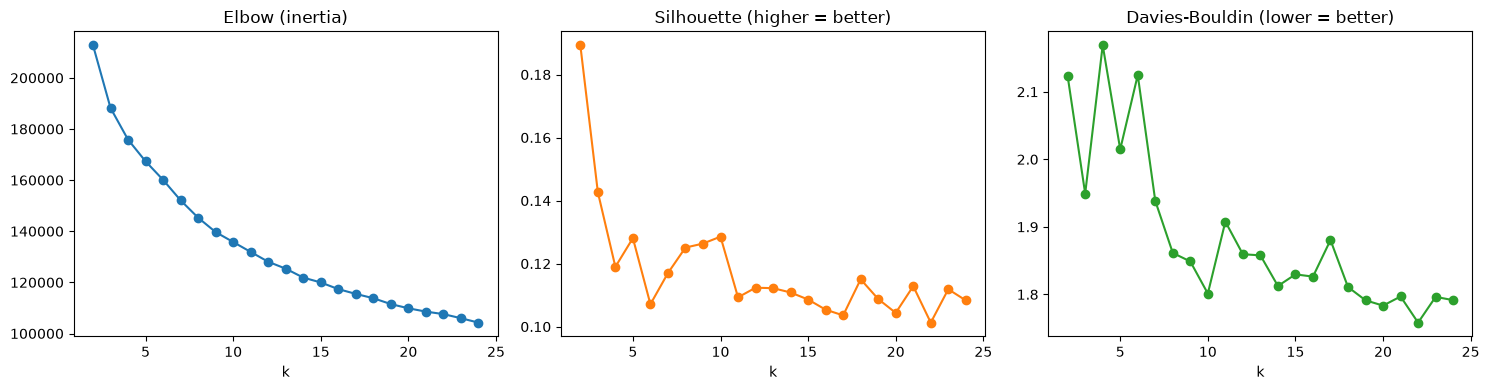

In [31]:
SIL_SAMPLE = min(10_000, len(Z))
ks = range(2, 25)
rows = []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Z)
    rows.append({'k': k, 'inertia': km.inertia_,
                 'silhouette': silhouette_score(Z, km.labels_, sample_size=SIL_SAMPLE,
                                                random_state=RANDOM_STATE),
                 'davies_bouldin': davies_bouldin_score(Z, km.labels_)})
scores = pd.DataFrame(rows).set_index('k')
display(scores.round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(ks, scores['inertia'], marker='o')
axes[0].set(title='Elbow (inertia)', xlabel='k')
axes[1].plot(ks, scores['silhouette'], marker='o', color='tab:orange')
axes[1].set(title='Silhouette (higher = better)', xlabel='k')
axes[2].plot(ks, scores['davies_bouldin'], marker='o', color='tab:green')
axes[2].set(title='Davies-Bouldin (lower = better)', xlabel='k')
plt.tight_layout()
plt.show()

In [37]:
from sklearn.metrics import log_loss

# Candidate cluster counts
# Reasonable size constraint: every training cluster must contain
# at least 2% of the training observations, and at least 20.
MIN_CLUSTER_SHARE = 0.02
MIN_CLUSTER_COUNT = 20

# One customer must not appear in both sets.
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=RANDOM_STATE,
)


X_train = X_done.loc[tr]
X_test = X_done.loc[te]
y_train = y.loc[tr].astype(int)
y_test = y.loc[te].astype(int)

# Fit preprocessing on training data only.
preprocessor = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
)

Z_train = preprocessor.fit_transform(X_train)
Z_test = preprocessor.transform(X_test)

K_VALUES = range(2, 21)  # Test K = 2 through 20

results = []
fitted_models = {}

for k in K_VALUES:
    model = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=RANDOM_STATE,
    )

    train_labels = model.fit_predict(Z_train)
    test_labels = model.predict(Z_test)

    # Estimate target probability for each training cluster
    cluster_rates = (
        pd.DataFrame({
            "cluster": train_labels,
            "target": y_train.to_numpy(),
        })
        .groupby("cluster")["target"]
        .agg(["sum", "count"])
    )

    # Laplace smoothing handles small or pure clusters
    cluster_rates["p_target"] = (
        (cluster_rates["sum"] + 1)
        / (cluster_rates["count"] + 2)
    )

    p_test = np.array([
        cluster_rates.loc[c, "p_target"]
        for c in test_labels
    ])

    ce = log_loss(
        y_test,
        np.column_stack([1 - p_test, p_test]),
        labels=[0, 1],
    )

    train_sizes = np.bincount(train_labels, minlength=k)

    results.append({
        "k": k,
        "cross_entropy": ce,
        "min_cluster_size": train_sizes.min(),
        "max_cluster_size": train_sizes.max(),
        "small_clusters_under_50": int((train_sizes < 50).sum()),
    })

    fitted_models[k] = model

results_df = (
    pd.DataFrame(results)
    .sort_values("cross_entropy")
    .reset_index(drop=True)
)

display(results_df)

best_k = int(results_df.iloc[0]["k"])
print(f"Best K: {best_k}")
print(f"Cross-entropy: {results_df.iloc[0]['cross_entropy']:.5f}")

,k,cross_entropy,min_cluster_size,max_cluster_size,small_clusters_under_50
0,19,0.622462,1,1468,4
1,18,0.624563,6,1409,4
2,16,0.625081,1,1489,4
3,20,0.627143,1,1438,4
4,15,0.631387,6,1682,3
5,11,0.632740,4,2582,2
6,12,0.632961,6,1607,2
7,17,0.637972,4,1767,4
8,8,0.638573,6,3059,2
9,10,0.639688,4,2977,3


Best K: 19
Cross-entropy: 0.62246


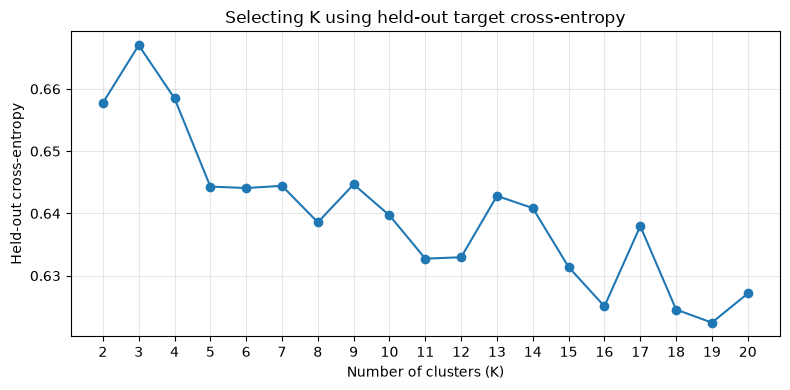

In [38]:
plot_df = results_df.sort_values("k")

plt.figure(figsize=(8, 4))
plt.plot(
    plot_df["k"],
    plot_df["cross_entropy"],
    marker="o",
)
plt.xlabel("Number of clusters (K)")
plt.ylabel("Held-out cross-entropy")
plt.title("Selecting K using held-out target cross-entropy")
plt.xticks(plot_df["k"])
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [43]:
# Clusters chosen
N_CLUSTERS = 8

km = KMeans(n_clusters=N_CLUSTERS, random_state=RANDOM_STATE, n_init=10)
labels = km.fit_predict(Z)

result = pd.DataFrame({
    OBS_ID: X_done.index,
    "cluster": labels,
    "target": y.reindex(X_done.index).to_numpy(),
}).set_index(OBS_ID)

# Profiles in original units are more interpretable than standardised values.
profile = X_done.assign(cluster=labels).groupby("cluster").mean(numeric_only=True)
profile["n_observations"] = result.groupby("cluster").size()
profile["target_rate"] = result.groupby("cluster")["target"].mean()

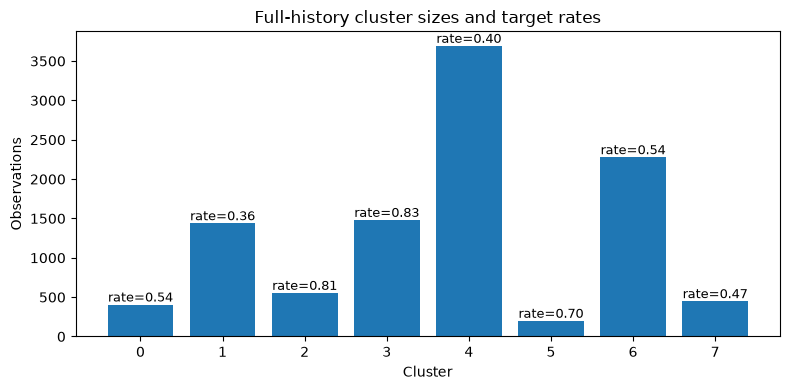

In [44]:
plot_data = profile.sort_index()
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(plot_data.index.astype(str), plot_data["n_observations"])
ax.set_xlabel("Cluster")
ax.set_ylabel("Observations")
ax.set_title("Full-history cluster sizes and target rates")
for bar, rate in zip(bars, plot_data["target_rate"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"rate={rate:.2f}",
        ha="center", va="bottom", fontsize=9,
    )
plt.tight_layout()
plt.show()

## Decision Tree

In [32]:
from sklearn.metrics import log_loss, roc_auc_score
from sklearn.tree import DecisionTreeClassifier, export_text

cols = X_clean.columns
prep = make_pipeline(SimpleImputer(strategy="median"), Winsorizer(1, 99))
Ztr, Zte = prep.fit_transform(X_clean.loc[tr]), prep.transform(X_clean.loc[te])

tree = DecisionTreeClassifier(max_leaf_nodes=25, min_samples_leaf=int(0.03 * len(tr)), random_state=0).fit(Ztr, y.loc[tr])
print(export_text(tree, feature_names=cols))        # the rules, in original units (no scaling needed for trees)

ltr, lte = tree.apply(Ztr), tree.apply(Zte)
rate = pd.Series(y.loc[tr].to_numpy()).groupby(ltr).mean()
pte  = pd.Series(lte).map(rate).to_numpy()
print("test AUC:", round(roc_auc_score(y.loc[te], pte), 3), "| log-loss:", round(log_loss(y.loc[te], pte, labels=[0, 1]), 4))

|--- income_p1 <= 3687.49
|   |--- run_n_bounced <= 4.50
|   |   |--- recent_vs_avg_income <= 0.52
|   |   |   |--- class: 1
|   |   |--- recent_vs_avg_income >  0.52
|   |   |   |--- new_to_arrears_flag <= 0.50
|   |   |   |   |--- run_income_slog <= 10.00
|   |   |   |   |   |--- avg_spend_between_pays <= 3783.85
|   |   |   |   |   |   |--- class: 1
|   |   |   |   |   |--- avg_spend_between_pays >  3783.85
|   |   |   |   |   |   |--- class: 1
|   |   |   |   |--- run_income_slog >  10.00
|   |   |   |   |   |--- class: 0
|   |   |   |--- new_to_arrears_flag >  0.50
|   |   |   |   |--- pay_gap_mean <= 30.25
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- pay_gap_mean >  30.25
|   |   |   |   |   |--- class: 0
|   |--- run_n_bounced >  4.50
|   |   |--- recent_vs_avg_income <= 1.03
|   |   |   |--- n_cycles <= 0.50
|   |   |   |   |--- run_in_income_informal_slog <= 6.14
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- run_in_income_informal_slog >  6.14
|   |   |   | 

## Log Regression

In [47]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import adjusted_rand_score

def fit_eval(a_ids, b_ids, k, weighted=True, floor=0.1, alpha=1, seed=0):
    prep = make_pipeline(SimpleImputer(strategy="median"), Winsorizer(1, 99), StandardScaler())
    Za, Zb = prep.fit_transform(X_clean.loc[a_ids]), prep.transform(X_clean.loc[b_ids])
    ya, yb = y.loc[a_ids], y.loc[b_ids]
    w = np.ones(Za.shape[1])
    if weighted:
        c = np.abs(LogisticRegression(C=0.1, max_iter=2000).fit(Za, ya).coef_[0])
        w = floor + (1 - floor) * c / c.max()
    km = KMeans(k, n_init=10, random_state=seed).fit(Za * w)
    la, lb = km.labels_, km.predict(Zb * w)
    s = pd.DataFrame({"c": la, "y": ya.to_numpy()}).groupby("c")["y"].agg(["sum", "count"])
    rate = ((s["sum"] + alpha) / (s["count"] + 2 * alpha)).reindex(range(k)).fillna(ya.mean())
    pb = rate.to_numpy()[lb]
    res = {"k": k, "weighted": weighted, "logloss": log_loss(yb, pb, labels=[0, 1]), "auc": roc_auc_score(yb, pb),
           "rate_spread": rate.max() - rate.min(), "min_share": np.bincount(la, minlength=k).min() / len(la)}
    return res, km, la, rate, lb          # lb = cluster labels of the b_ids rows

In [48]:
tr, te = split(y, groups)
K = 8
res, km, la, rate, lb = fit_eval(tr, te, K, weighted=True)
print({k: round(float(v), 4) for k, v in res.items()})

{'k': 8.0, 'weighted': 1.0, 'logloss': 0.6103, 'auc': 0.7149, 'rate_spread': 0.559, 'min_share': 0.0414}


In [49]:
prep = make_pipeline(SimpleImputer(strategy="median"), Winsorizer(1, 99), StandardScaler())
Ztr, Zte = prep.fit_transform(X_clean.loc[tr]), prep.transform(X_clean.loc[te])
p_lg = LogisticRegression(C=0.1, max_iter=2000).fit(Ztr, y.loc[tr]).predict_proba(Zte)[:, 1]

print(pd.DataFrame({
    "model": ["weighted clusters", "logistic (same inputs)"],
    "test_auc": [res["auc"], roc_auc_score(y.loc[te], p_lg)],
    "test_logloss": [res["logloss"], log_loss(y.loc[te], p_lg)]}).round(4))

                    model  test_auc  test_logloss
0       weighted clusters    0.7149        0.6103
1  logistic (same inputs)    0.7713        0.5682


In [50]:
rows = []
for s in range(1, 6):                                   # different K-means starts
    r, _, _, _, lb_s = fit_eval(tr, te, K, True, seed=s)
    rows.append({"test": "kmeans seed", "run": s, "ARI_vs_base": adjusted_rand_score(lb, lb_s),
                 "auc": r["auc"], "logloss": r["logloss"]})
for s in range(1, 6):                                   # different 80% subsets of the training customers
    sub, _ = split(y.loc[tr], groups, test_size=0.2, seed=s)
    r, _, _, _, lb_s = fit_eval(sub, te, K, True)
    rows.append({"test": "80% of customers", "run": s, "ARI_vs_base": adjusted_rand_score(lb, lb_s),
                 "auc": r["auc"], "logloss": r["logloss"]})

stab = pd.DataFrame(rows)
print(stab.round(3).to_string(index=False))
print(stab.groupby("test")["ARI_vs_base"].agg(["mean", "min"]).round(3))

            test  run  ARI_vs_base   auc  logloss
     kmeans seed    1        0.657 0.715    0.607
     kmeans seed    2        0.984 0.714    0.610
     kmeans seed    3        0.987 0.708    0.611
     kmeans seed    4        0.994 0.709    0.610
     kmeans seed    5        0.993 0.709    0.611
80% of customers    1        0.711 0.717    0.607
80% of customers    2        0.947 0.716    0.609
80% of customers    3        0.654 0.716    0.607
80% of customers    4        0.924 0.712    0.610
80% of customers    5        0.907 0.707    0.613
                   mean    min
test                          
80% of customers  0.829  0.654
kmeans seed       0.923  0.657


In [51]:
def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z**2 / n; c = (p + z**2 / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return c - h, c + h

t = pd.DataFrame({"c": lb, "y": y.loc[te].to_numpy()}).groupby("c")["y"].agg(["sum", "count"])
lo, hi = wilson(t["sum"].to_numpy(), t["count"].to_numpy())
seg = pd.DataFrame({"n_test": t["count"], "share": t["count"] / t["count"].sum(),
                    "rate_train": rate.reindex(t.index).to_numpy(),
                    "rate_test": t["sum"] / t["count"], "ci_low": lo, "ci_high": hi}
                   ).sort_values("rate_test", ascending=False)
print(seg.round(3))

# What defines each segment, in original units (the 15 features that differ most between segments)
med = X_clean.loc[te].assign(c=lb).groupby("c").median()
top = ((med.max() - med.min()) / X_clean.loc[te].std()).sort_values(ascending=False).head(15).index
print(med.loc[seg.index, top].T.round(2))

   n_test  share  rate_train  rate_test  ci_low  ci_high
c                                                       
0     194  0.092       0.797      0.861   0.805    0.903
5      69  0.033       0.889      0.826   0.720    0.898
3     356  0.170       0.764      0.787   0.741    0.826
4     135  0.064       0.494      0.519   0.435    0.601
6     430  0.205       0.483      0.467   0.421    0.515
1     143  0.068       0.407      0.462   0.382    0.543
2     192  0.092       0.330      0.375   0.310    0.445
7     579  0.276       0.330      0.320   0.283    0.359
c                                   0        5         3         4         6  \
no_income_detected               0.00      1.0      0.00      0.00      0.00   
no_income_seen                   0.00      1.0      0.00      0.00      0.00   
run_income_slog                  9.57      0.0      9.61      9.24     10.35   
days_since_last_income          20.00     95.0     36.00     16.00     12.00   
recent_vs_avg_income          